## 1) Diferenciación numérica

No me hagan derivar a altas horas de la noche, por favor.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

In [19]:
def f(x):
    return 1 + (1/2)*np.tanh(2*x) #listo, función definida

In [20]:
x = np.linspace(-2,2,1000) #intervalo solicitado

h=0.000001
dfc = (f(x+h/2)-f(x-h/2))/(h) #la formulita mágica

En cuanto al resultado analítico, me salió: $f'(x) = sech^{2} (2x)$

In [23]:
fanal = (np.cosh(2*x))**(-2)

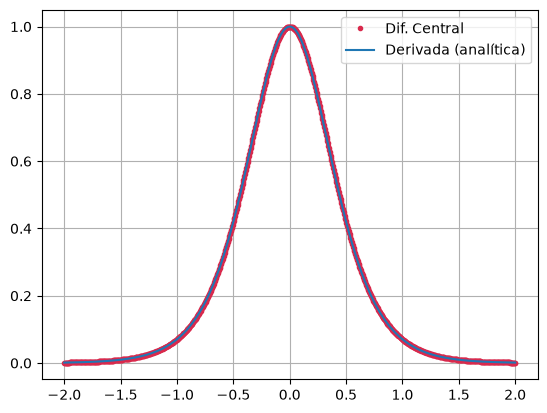

In [30]:
plt.plot(x,dfc, '.', label = 'Dif. Central', color = '#D9294C')
plt.plot(x,fanal, label = 'Derivada (analítica)')
plt.legend()
plt.grid()

## 2) Campo eléctrico de una distribución de cargas

¿Bastará con aproximar r como escalar? En principio, yo digo que sí porque numpy hace magia con los arreglos, entonces no tendría que programar ningún gradiente aun. A ver qué sale, lo intentaré 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [25]:
e0 = 8.854187 * (10**(-12)) #permitividad del vacío
def phi(r,q):
    return q/(4*np.pi*e0*r) #defino, con fé, el potencial eléctrico

In [26]:
X = np.linspace(-1,1,500)
Y = np.linspace(-1,1,500)
x,y= np.meshgrid(X,Y)
r = np.sqrt(x**2+y**2) #todo bien hasta aquí
h = 0.001

In [29]:
E = (phi(r+h/2, 1)-phi(r-h/2, 1))/(-h) #Así calcularía el campo eléctrico si tuviera fé

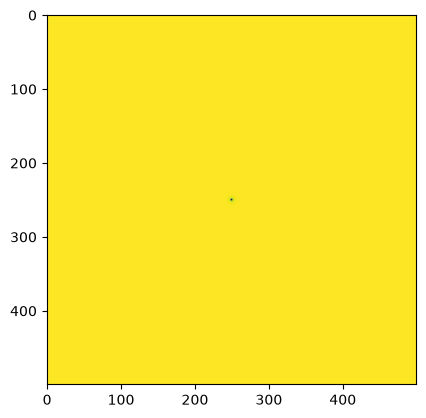

In [30]:
plt.imshow(E)

La razón de que esto no sea suficiente es que, efectivamente, una derivada sobre r no es el gradiente. Pero sí puedo obtener el gradiente a partir de la derivada de r: $\frac{\partial \phi}{\partial x} = \frac{d \phi}{d r}\frac{\partial r}{\partial x}$, $\frac{\partial \phi}{\partial y} = \frac{d \phi}{d r}\frac{\partial r}{\partial y}$

Cada una de esas parciales es simplemente $x_i / r$. Juntaré todo en un solo programa, solo por tener fé

In [2]:
import numpy as np
import matplotlib.pyplot as plt


e0 = 8.854187 * (10**(-12)) #permitividad del vacío
def phi(r,q):
    return q/(4*np.pi*e0*r)

X = np.linspace(-1,1,500)
Y = np.linspace(-1,1,500)
x,y= np.meshgrid(X,Y)
r = np.sqrt(x**2+y**2) 
h = 0.001


dr = (phi(r+h, 1)-phi(r-h, 1))/(2*h) #derivada de r

Ex,Ey = -dr*(x/r), dr*(y/r) #fé

E = np.sqrt(Ex**2 + Ey**2) #magnitud

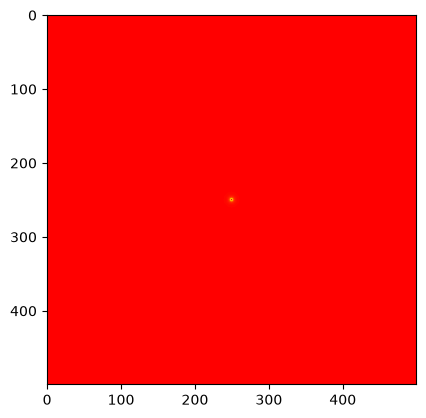

In [45]:
plt.imshow(E)
plt.hsv()

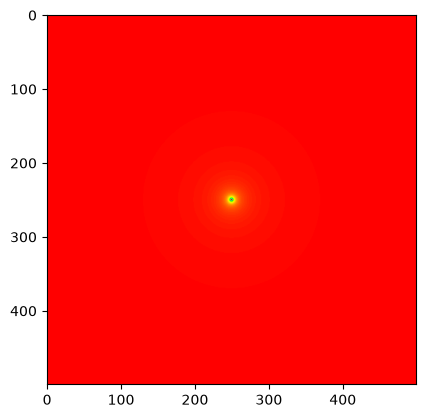

In [49]:
p = phi(r,1)
plt.imshow(p)
plt.hsv()

Ok. Suficiente práctica. Va a estar feo (me convendrá cambiar las unidades para que no se vea tan chiquito wwwww).

a) El potencial eléctrico total simplemente será la suma de los dos potenciales. Dado que me piden colocar las cargas en medio de un cuadrado, tendré que cambiar un poquito las expresiones para cada una:

$\phi(r) = k_E q (\frac{1}{|r-a_1|} - \frac{1}{|r-a_2|})$, con $k_E = \frac{1}{4 \pi \epsilon_0} \simeq 8.98 \times 10^{9} F/m = 8.98 \times 10^{7} F/cm$ la constante correspondiente, $a_1 = (-5,0)$ la posición de la carga positiva y $a_2 = (5,0)$.

Creo que eso debería ser suficiente para hacer el código.

In [4]:
kE = 8.98*(10**7) #constante
q = 1 #coulomb
X = np.arange(-100,100,1)
Y = np.arange(-100,100,1) #esta vez usé arange para hacer que la separación entre los puntos sea de un centímetro.
x,y= np.meshgrid(X,Y) #plano

r1 = np.sqrt((x+5)**2 + y**2) #las distancias a la carga 1
r2 = np.sqrt((x-5)**2  + y**2) #las distancias a la carga 2

p = kE*q*(1/r1 - 1/r2) #listo

/tmp/ipykernel_7532/2321404602.py:10: RuntimeWarning: divide by zero encountered in divide
  p = kE*q*(1/r1 - 1/r2) #listo


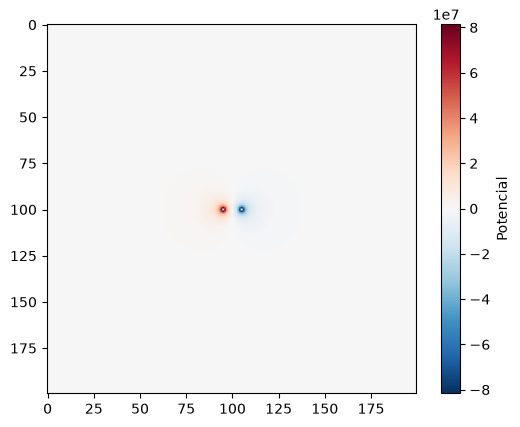

In [5]:
plt.imshow(p, cmap='RdBu_r') #estos colores son muy bonitos
plt.colorbar(label = 'Potencial')

Para el campo eléctrico hay que derivar phi, así que tengo que pasar mi phi a una función. Luego uso diferencias centrales en cada entrada.

In [6]:
def phi(x,y):
    kE = 8.98*(10**7) #constante
    q = 1 #coulomb
    return kE*q*(1/np.sqrt((x+5)**2 + y**2) - 1/np.sqrt((x-5)**2 + y**2)) #función para mi potencial, con xy en centímetros.

In [7]:
kE = 8.98*(10**7) #constante
q = 1 #coulomb
X = np.arange(-100,100,1)
Y = np.arange(-100,100,1) #esta vez usé arange para hacer que la separación entre los puntos sea de un centímetro.
x,y= np.meshgrid(X,Y) #plano
h=0.001

def phi(x,y):
    kE = 8.98*(10**7) #constante
    q = 1 #coulomb
    return kE*q*(1/np.sqrt((x+5)**2 + y**2) - 1/np.sqrt((x-5)**2 + y**2)) #función para mi potencial, con xy en centímetros.


Ex = (phi(x+h, y)-phi(x-h, y))/(-2*h) #componente x
Ey = (phi(x, y+h)-phi(x, y-h))/(-2*h) #componente y

Vi que la gráfica con flechas la puedo sacar de dos formas, con una función que se llama quiver (flechas) y otra que se llama streamplot (flujos)

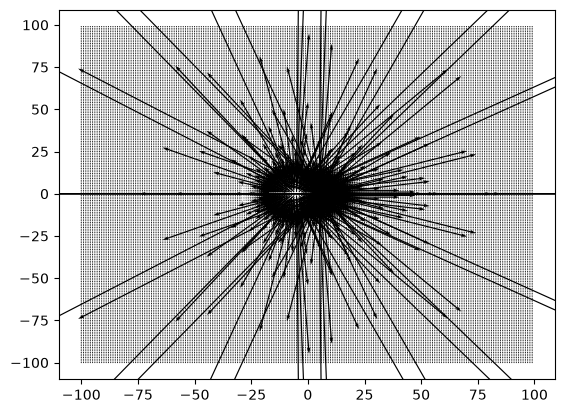

In [8]:
plt.quiver(x,y,Ex,Ey) #a esto hay que moverle porque se son muchas flechas, y muy largas wwwww

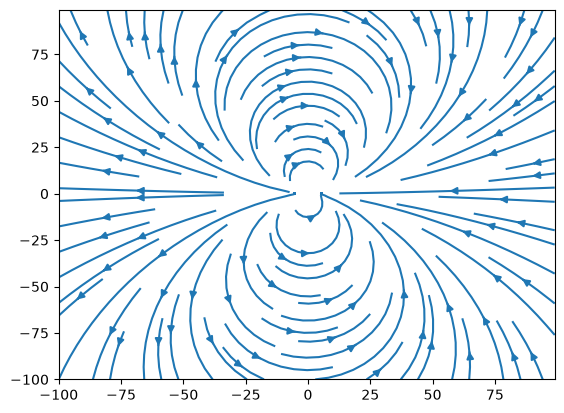

In [9]:
plt.streamplot(x,y,Ex,Ey) #este ya se ve decente así sin hacerle nada, pero quiero modificar el otro

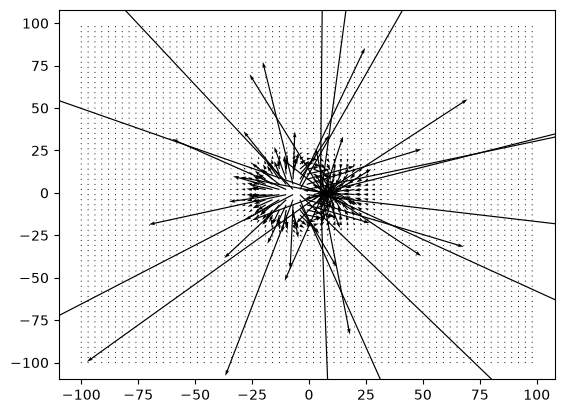

In [10]:
plt.quiver(x[::3,::3],y[::3,::3],Ex[::3,::3],Ey[::3,::3]) #solo grafico algunos puntos. Pero hay unas flechas que simplemente son muy grandes. Se soluciona normalizando

Text(0.5, 1.0, 'Campo Eléctrico de un dipolo')

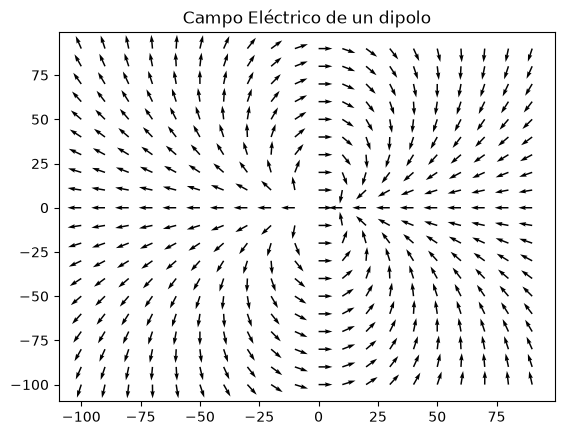

In [11]:
E = np.sqrt(Ex**2 + Ey**2) #norma del campo
Exn, Eyn = Ex/E, Ey/E #normalización
plt.quiver(x[::10,::10],y[::10,::10],Exn[::10,::10],Eyn[::10,::10]) #bastante más sabroso
plt.title('Campo Eléctrico de un dipolo')

c) No me hagan eso, por favor

Primero, reciclaré el código para la cuadratura de Gauss de dos variables de la tarea pasada. Aquí, convenientemente, el intervalo de integración también es idéntico en ambas coordenadas, así que aun no necesito modificar el código aquél.

In [12]:
def gauss2(f,a,b,n): #en principio, ocuparé las mismas entradas. El intervalo de integración lo dejo igual porque, al menos, para este ejercicio es el mismo en ambas coordenadas.
    import numpy as np
    from scipy.special import roots_legendre
    x_i, w_i = roots_legendre(n) #saco las raíces y puntos para la primera coordenada
    y_j, w_j = roots_legendre(n) #saco las raíces y puntos para la segunda coordenada
    I = 0 #parto de algún punto, 0 está bien
    for i in range(n):
        xi = ((b-a)/2)*x_i[i]+(b+a)/2 #reescalo los puntos de la primera coordenada
        for j in range(n):
            yj = ((b-a)/2)*y_j[j]+(b+a)/2 #reescalo los puntos de la segunda coordenada. Es importante que vayan en for diferentes para que se combinen los índices.
            I = I +w_i[i]*w_j[j]*f(xi,yj) #cambiará la definición de f.
    return (((b-a)/2)**2)*I #la constante va al cuadrado porque ahora hay dos contribuciones

La integral a realizar es: $\phi(\bar{r}) = \frac{1}{4\pi \epsilon_0}\displaystyle\int_{-L/2}^{L/2} \int_{-L/2}^{L/2} \sigma(x',y') G(\bar{r}, \bar{r}') dx'dy'$, tomando la distribución de carga en el centro. G es la función de Green en el vacío en coordenadas cartesianas: $G(\bar{r}, \bar{r}') = \frac{1}{|\bar{r} - \bar{r}'|}$, las coordenadas primadas son respecto de las cargas de la distribución, las no primadas son respecto del observador, i. e., estas son las que irán en un plano con un centímetro de separación entre sí. Para esto, voy a necesitar una integral por cada punto de observación, así que hay que definir a phi de manera conveniente.

In [39]:
#constantes:
ep0=8.85419 * (10**(-12))
q0 = 100
L = 0.1 #10 centímetros


#lo demás:

def phi(x,y,n): #pongo los nodos de la cuadratura de Gauss desde acá porque se ocuparán después
    def f(xp,yp): #el integrando
        sig = q0*np.sin((2*np.pi*xp)/L)*np.sin((2*np.pi*yp)/L) #distribución de carga
        g = 1/np.sqrt((x-xp)**2 + (y-yp)**2) #función de Green
        return sig*g #defino el integrando

    return gauss2(f,-L/2,L/2,n)/(4*np.pi*ep0) #integro sobre todo el cuadrado en el punto x,y


In [42]:
X = np.arange(-0.5,0.5,0.01)
Y = np.arange(-0.5,0.5,0.01) #creo que esto es un métro cuadrado de plano
x,y= np.meshgrid(X,Y) #plano
L = 0.1 #10 centímetros

In [43]:
phi(x,y,10)

array([[  9674551.53879595,   9967463.31323766,  10264760.41937487, ...,
        -10565893.83596839, -10264760.41937464,  -9967463.31323761],
       [  9967463.31323755,  10279740.89717512,  10597392.80323186, ...,
        -10919885.90114876, -10597392.80323185, -10279740.89717491],
       [ 10264760.41937493,  10597392.80323183,  10936494.24228521, ...,
        -11281555.13870374, -10936494.24228494, -10597392.80323179],
       ...,
       [-10565893.83596833, -10919885.90114874, -11281555.1387038 , ...,
         11650424.29059047,  11281555.13870397,  10919885.90114878],
       [-10264760.41937494, -10597392.80323158, -10936494.24228489, ...,
         11281555.13870391,  10936494.242285  ,  10597392.80323163],
       [ -9967463.31323756, -10279740.89717502, -10597392.80323193, ...,
         10919885.90114856,  10597392.80323193,  10279740.89717477]],
      shape=(100, 100))

Ahora derivo:

Text(0.5, 1.0, 'Campo Eléctrico para la distribución de carga')

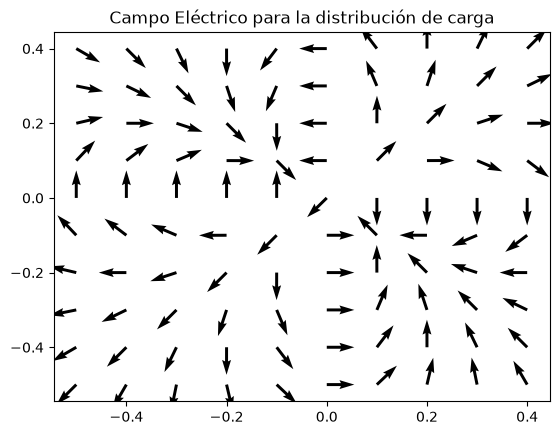

In [49]:
h=0.001
Ex = (phi(x+h, y,10)-phi(x-h, y,10))/(-2*h) #componente x
Ey = (phi(x, y+h,10)-phi(x, y-h,10))/(-2*h) #componente y
E = np.sqrt(Ex**2 + Ey**2) #norma del campo
Exn, Eyn = Ex/E, Ey/E #normalización
plt.quiver(x[::10,::10],y[::10,::10],Exn[::10,::10],Eyn[::10,::10]) #bastante más sabroso
plt.title('Campo Eléctrico para la distribución de carga')

## 3) Procesamiento de Imágentes y STM

a) Ese archivo está bastante feo. Si no entiendo mal las instrucciones, cada uno de los numerotes que están ahí puestos siguen la estructura: w(x,y)=a, donde la x va de 0 a 14, y la y no tengo ni remota idea.

In [53]:
#vi que numpy puede hacer eso con una simple función.
m = np.loadtxt("altitudes.txt")

In [55]:
m #así, w(x,y) = m[x][y]

array([[-4116.06, -4114.78, -4113.87, ..., -4122.67, -4120.08, -4117.81],
       [-3969.33, -3959.2 , -3949.72, ..., -4007.06, -3993.46, -3980.39],
       [-2652.85, -2647.95, -2648.86, ..., -2720.04, -2691.39, -2666.93],
       ...,
       [ 2981.16,  2979.56,  2977.87, ...,  2986.03,  2984.54,  2982.82],
       [ 2897.12,  2896.19,  2895.3 , ...,  2900.22,  2899.22,  2898.19],
       [ 2785.31,  2785.22,  2785.14, ...,  2785.62,  2785.57,  2785.44]],
      shape=(512, 1024))

In [196]:
#Funciona perfecto, pero creo que no querían que usáramos eso. wwwwwww. Por cierto, en mis sueños la x iba de 0 a 14 wwwwwwwwwwww.
archivo = open("altitudes.txt","r") #abro el archivo
líneas = []

for línea in archivo:
    líneas.append(línea) #meto cada línea en la lista de líneas (vaya).

matriz = [] #aquí voy a colocar cada fila

for línea in líneas:
    fila = línea.split() #split spliteaba (vaya) cada línea en sus partes
    fila = [float(entrada) for entrada in fila] #los vuelvo flotantes
    matriz.append(fila)

w = np.array(matriz) #lo vuelvo un arreglo de numpy porque son más bonitos

In [197]:
w #listo, ahora w(x,y) = w[y,x]. Por algún motivo.

array([[-4116.06, -4114.78, -4113.87, ..., -4122.67, -4120.08, -4117.81],
       [-3969.33, -3959.2 , -3949.72, ..., -4007.06, -3993.46, -3980.39],
       [-2652.85, -2647.95, -2648.86, ..., -2720.04, -2691.39, -2666.93],
       ...,
       [ 2981.16,  2979.56,  2977.87, ...,  2986.03,  2984.54,  2982.82],
       [ 2897.12,  2896.19,  2895.3 , ...,  2900.22,  2899.22,  2898.19],
       [ 2785.31,  2785.22,  2785.14, ...,  2785.62,  2785.57,  2785.44]],
      shape=(512, 1024))

Ahora, para calcular las derivadas, efectivamente, se ocuparán varios métodos. Intuitivamente, creo que puedo usar derivadas a la derecha en los bordes izquierdos y derivadas izquierdas en los bordes derechos, y centrales para todo lo demás. A ver qué sale.

Los bordes izquierdos estarán dados por $w(0,y)$, y los derechos por $w(1023,y)$ (o bien, por [x] = [-1]). Así también cuando calcule derivadas sobre las filas.

Hint random: cuando tengamos un conjunto de datos fijo, usar diferencias centrales cambia un poco (pues no podemos tomar índices intermedios), en tal caso se recomienda aproximar con una variable $H = 2h$ en su lugar

Realizaré, entonces, las derivadas asumiendo que la diferencia h entre cada punto es de $h=30,000 \ m$

In [198]:
h=30000

#parciales respecto de x

dwxd = (w[:,1]-w[:,0])/(h) #derivadas a la derecha del borde izquierdo. Sumé uno a cada entrada para obtener w(x+h,0).
dwxi = -(w[:,-2] - w[:,-1])/h #derivadas a la izquierda del borde derecho. Uso los signos negativos para no depender del tamaño de la matriz
dwxc = (w[:,2:] - w[:,:-2])/(2*h) #derivadas centrales de todos los puntos en medio

#parciales respecto de y

dwyd = (w[1,:]-w[0,:])/(h) #derivadas hacia abajo en el primer renglón.
dwyi = -(w[-2,:] - w[-1,:])/h #derivadas hacia arriba en el último renglón.
dwyc = (w[2:,:] - w[:-2,:])/(2*h) #derivadas centrales de todos los puntos en medio

Nunca voy a manejar esa sintaxis con soltura, pero al menos le entiendo.

b) Para realizar las cuentas, ocupo tener todas las parciales de x e y en matrices correspondientes. Puedo hacer eso con matrices de ceros idénticas en tamaño a w y luego sustituir sus columnas y renglones con las respectivas derivadas. Esto es:

In [199]:
dwx = np.zeros(w.shape)
dwy = np.zeros(w.shape)

In [200]:
dwx #mismo tamaño que w

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(512, 1024))

In [201]:
#parciales de x

dwx[:,0] = dwxd #en la primera columna, pongo todas las derivadas de la primera columna
dwx[:,-1] = dwxi #en la última columna, pongo todas las derivadas de la última columna
dwx[:,1:-1] = dwxc #en las columnas del medio meto las derivadas del medio

#parciales de y

dwy[0,:] = dwyd #en el primer renglón, pongo todas las derivadas del primer renglón
dwy[-1,:] = dwyi #en el último renglón, pongo todas las derivadas del último renglón
dwy[1:-1,:] = dwyc #en los renglones del medio meto las derivadas del medio.


Ahora, simplemente meto los formulazos considerando que $cos(45°) = sin(45°) = \sqrt{2}/2$

In [202]:
I = (np.sqrt(2)/2)*(dwx+dwy)/np.sqrt(dwx**2 + dwy**2 + 1) #esta cosa ya debería ser un arreglo bidimensional que se pueda graficar con imshow.

Text(0.5, 1.0, 'Relieve del Mundo (aproximado)')

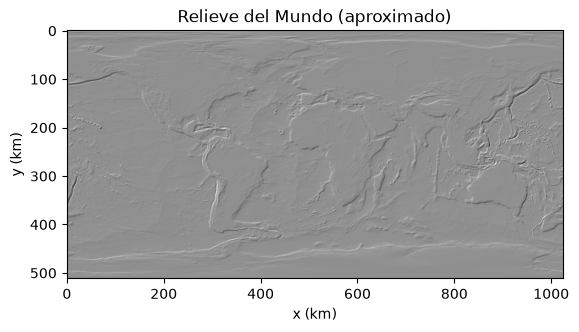

In [203]:
plt.imshow(I)
plt.gray()
plt.xlabel('x (km)')
plt.ylabel('y (km)')
plt.title('Relieve del Mundo (aproximado)')

Para mí, ya se ve bastante decente esa gráfica. Debo ser sincero, no pensé que esto fuera a funcionar hasta que compilé ese último cuadro.

c) Creo que basta con copiar y pegar todo el código anterior, cambiando únicamente el archivo de texto.

Text(0.5, 1.0, 'STM del Silicio')

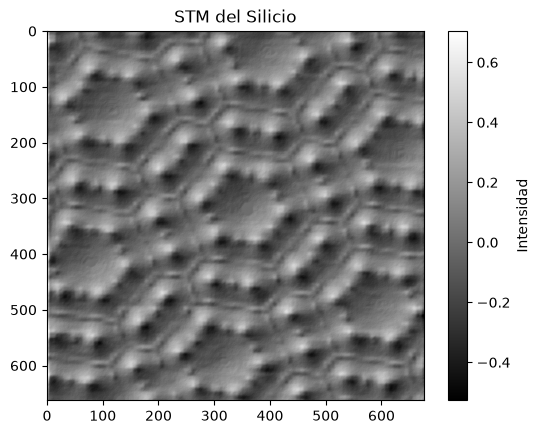

In [211]:
#obteniendo datos------------------------------------------------------------------------------------------------------------------------------------

archivo = open("stm.txt","r") #abro el archivo
líneas = []

for línea in archivo:
    líneas.append(línea) #meto cada línea en la lista de líneas (vaya).

matriz = [] #aquí voy a colocar cada fila

for línea in líneas:
    fila = línea.split() #split spliteaba (vaya) cada línea en sus partes
    fila = [float(entrada) for entrada in fila] #los vuelvo flotantes
    matriz.append(fila)

w = np.array(matriz) #lo vuelvo un arreglo de numpy porque son más bonitos

#derivando. Valió la pena escribir las fórmulas sin utilizar explícitamente el tamaño de la matriz, literalmente lo puedo reciclar gracias a eso.---------------------------------

h=2.5

#parciales respecto de x

dwxd = (w[:,1]-w[:,0])/(h) #derivadas a la derecha del borde izquierdo. Sumé uno a cada entrada para obtener w(x+h,0).
dwxi = -(w[:,-2] - w[:,-1])/h #derivadas a la izquierda del borde derecho. Acá resulta conveniente conocer el tamaño de la matriz
dwxc = (w[:,2:] - w[:,:-2])/(2*h) #derivadas centrales de todos los puntos en medio

#parciales respecto de y

dwyd = (w[1,:]-w[0,:])/(h) #derivadas hacia abajo en el primer renglón.
dwyi = -(w[-2,:] - w[-1,:])/h #derivadas hacia arriba en el último renglón.
dwyc = (w[2:,:] - w[:-2,:])/(2*h) #derivadas centrales de todos los puntos en medio

#Construyendo el gradiente----------------------------------------------------------------------------------------------------------------------------

dwx = np.zeros(w.shape)
dwy = np.zeros(w.shape)

#parciales de x

dwx[:,0] = dwxd #en la primera columna, pongo todas las derivadas de la primera columna
dwx[:,-1] = dwxi #en la última columna, pongo todas las derivadas de la última columna
dwx[:,1:-1] = dwxc #en las columnas del medio meto las derivadas del medio

#parciales de y

dwy[0,:] = dwyd #en el primer renglón, pongo todas las derivadas del primer renglón
dwy[-1,:] = dwyi #en el último renglón, pongo todas las derivadas del último renglón
dwy[1:-1,:] = dwyc #en los renglones del medio meto las derivadas del medio.

#calculando intensidad. No me dieron el ángulo, así que lo tomaré general. ------------------------------------------------------------------------------

phi = np.pi/4

I = (dwx*np.cos(phi) + dwy*np.sin(phi))/np.sqrt(dwx**2 + dwy**2 + 1)

plt.imshow(I)
plt.colorbar(label = 'Intensidad')
plt.title('STM del Silicio')



## 4) Derivación mediante integración compleja.

Fingiré que entendí toda la explicación (recursé Variable Compleja) y saltaré al resultado final. Tengo que programar lo siguiente:

$\left( \frac{d^m f}{dz^m} \right)_{z=0} \simeq \frac{m!}{N} \displaystyle\sum_{k=0}^{N-1} f(z_k) e^{-2i \pi k m /N}$

Con: $z_k = e^{2i \pi k /N}$

In [217]:
from cmath import exp
from math import factorial #importo las funciones que me sugirieron

In [218]:
def f(z):
    return exp(2*z) #defino a la función a derivar.

In [222]:
def devchy(f,m,N): #Intentaré hacerlo de una como función. Ocuparé la función a derivar, el orden y el número de puntos.
    I = 0
    for k in np.arange(N):
        z_k = exp((2*1j*np.pi*k)/N)
        I = I + f(z_k)*exp((-2*1j*np.pi*k*m)/N)
    return I*factorial(m)/N

In [238]:
for i in range(20):
    print(devchy(f,i,10000))

(1.0000000000000022+2.232488499620544e-16j)
(1.9999999999999925+1.7933068224840198e-16j)
(3.9999999999999907+2.9825690528451078e-16j)
(8.000000000000009-1.6113371054116144e-15j)
(16.000000000000025+1.844970010100866e-15j)
(32.00000000000009-1.0431613906014548e-14j)
(64.00000000000028-1.4936551995248237e-13j)
(128.0000000000023+3.410122184632769e-14j)
(256.0000000000045-7.700560189505267e-12j)
(512.0000000000471+1.0496928926073679e-10j)
(1024.0000000020225-8.263525863583254e-11j)
(2048.000000017239+6.184928569297199e-09j)
(4095.999999925821+1.0906823780132413e-07j)
(8192.000001283926-1.3215534359645176e-06j)
(16383.999996798217+9.699422909008604e-06j)
(32768.00002993427-0.00021044896115363088j)
(65536.00529497997-0.001783548820952774j)
(131072.01811428563-0.11552082734471014j)
(262145.6787912915-0.11165877994418452j)
(524318.2146866899+29.419818377767694j)


Puede verse cómo hay errores de punto flotante volando por ahí (y las partes imaginarias de repente dejan de ser cero), pero sí que jala. Adiós.